# 1. EDA Setup & Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project paths
DATA_DIR = Path("../data/raw/m5")
PROCESSED_DIR = Path("../data/processed")

SALES_PATH = DATA_DIR / "sales_train_validation.csv"
PRICE_PATH = DATA_DIR / "sell_prices.csv"
CALENDAR_PATH = PROCESSED_DIR / "calendar_cleaned.csv"

# Load cleaned calendar
calendar = pd.read_csv(
    CALENDAR_PATH,
    parse_dates=["date"]
)

# Read sales column names only
sales_header = pd.read_csv(SALES_PATH, nrows=0)

daily_columns = [
    col for col in sales_header.columns
    if col.startswith("d_")
]

print("EDA Environment Ready!")
print("Calendar Shape:", calendar.shape)
print("Daily Sales Columns:", len(daily_columns))
print("Date Range:", calendar["date"].min(), "to", calendar["date"].max())
print("Sales File Exists:", SALES_PATH.exists())

EDA Environment Ready!
Calendar Shape: (1969, 14)
Daily Sales Columns: 1913
Date Range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00
Sales File Exists: True


# 2. Daily Total Sales Analysis

Calculating 1,913 days of combined daily demand.

In [3]:
# Calculate total daily sales across all products and stores
daily_sales = np.zeros(len(daily_columns), dtype=np.int64)

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):
    daily_sales += chunk[daily_columns].sum().to_numpy(dtype=np.int64)

# Create a DataFrame with dates and sales
daily_sales_df = pd.DataFrame({
    "date": calendar.set_index("d").loc[daily_columns, "date"].values,
    "total_sales": daily_sales
})

daily_sales_df = daily_sales_df.sort_values("date").reset_index(drop=True)

# Display summary
print("Daily Sales Summary:")
display(daily_sales_df.head())

print("\nStatistical Summary:")
print(daily_sales_df["total_sales"].describe())

Daily Sales Summary:


,date,total_sales
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146



Statistical Summary:
count     1913.000000
mean     34341.562467
std       7345.905196
min         11.000000
25%      29654.000000
50%      33732.000000
75%      38689.000000
max      57218.000000
Name: total_sales, dtype: float64


Minimum sales of just 11 units seems unusually low compared with the avg . 
#
We'll inspect that date, before drawing conclusions

# 3. Daily Sales Trend Visualisation

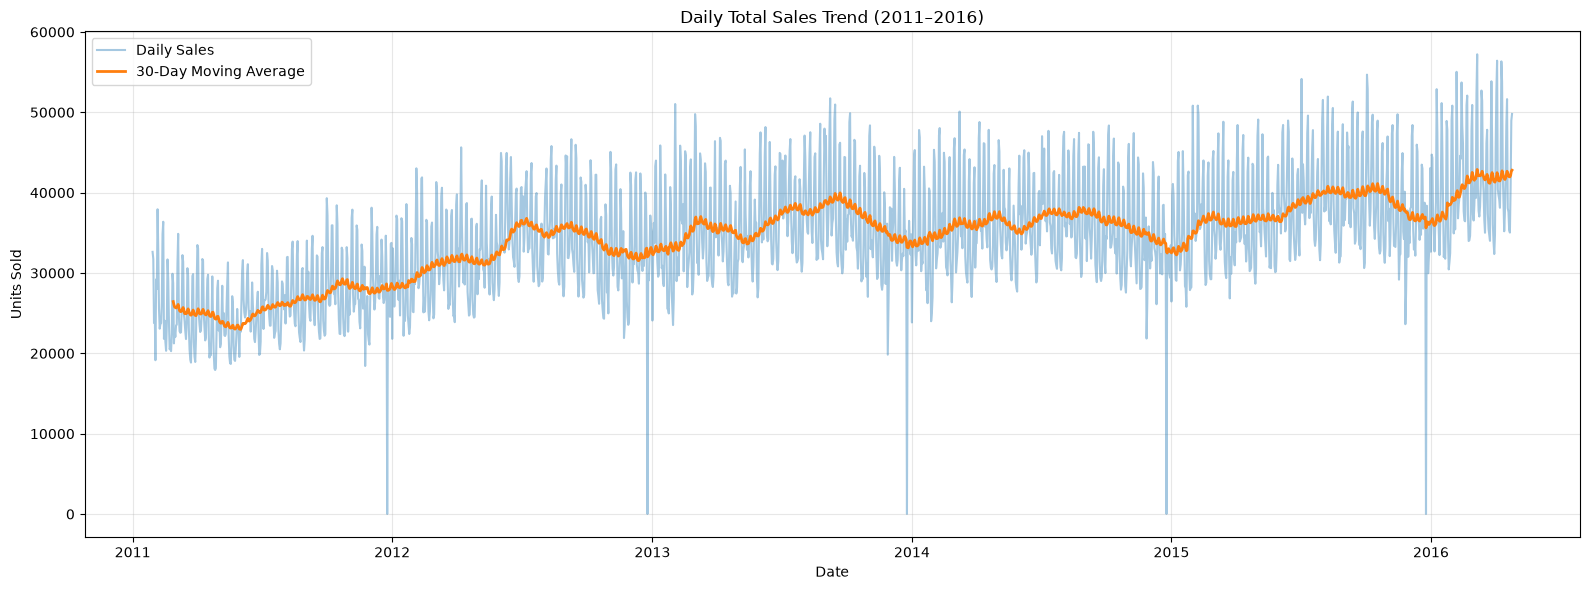

Lowest Sales Day:


date           2012-12-25 00:00:00
total_sales                     11
Name: 696, dtype: object

In [4]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales_df["date"],
    daily_sales_df["total_sales"],
    label="Daily Sales",
    alpha=0.4
)

plt.plot(
    daily_sales_df["date"],
    daily_sales_df["total_sales"].rolling(30).mean(),
    label="30-Day Moving Average",
    linewidth=2
)

plt.title("Daily Total Sales Trend (2011–2016)")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Investigate minimum sales date
print("Lowest Sales Day:")
display(
    daily_sales_df.loc[
        daily_sales_df["total_sales"].idxmin()
    ]
)

#### What we discovered
1. Overall upward trend

The orange 30-day moving average generally increases from around 25K units in 2011 to over 42K in 2016. This suggests overall demand increased over the historical period.

2. Weekly fluctuations

The repeated up-and-down pattern in blue suggests strong weekly seasonality. We'll investigate which weekdays have higher sales.

3. Christmas effect

Notice those huge drops around December every year?

Our lowest sales day is 25 December 2012, with just 11 units. This is consistent with Walmart's Christmas closure pattern. We should investigate these dates rather than treating them as ordinary demand drops.

# 4. Weekday Sales Analysis

Identifying which days have the highest average sales to figureout :-
#
Do customers buy more on weekends, weekdays, or particular days?

Average Sales by Weekday:


,weekday,total_sales
0,Saturday,41546.894161
1,Sunday,41130.021898
2,Monday,32852.967033
3,Tuesday,30368.780220
4,Wednesday,30010.021978
5,Thursday,30205.007326
6,Friday,34225.985348


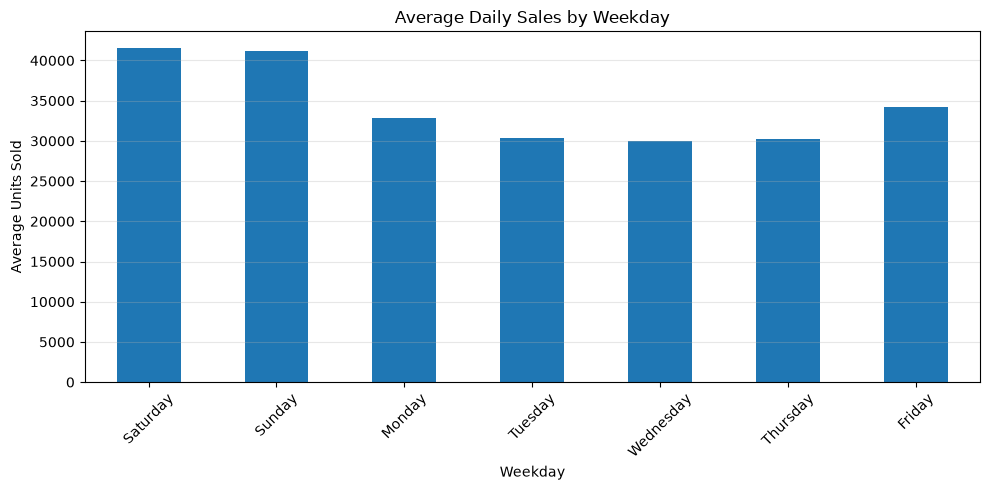

In [5]:
# Merge daily sales with calendar information
sales_calendar = daily_sales_df.merge(
    calendar[["date", "weekday"]],
    on="date",
    how="left"
)

# Maintain actual weekday order from calendar
weekday_order = (
    calendar["weekday"].drop_duplicates().tolist()
)

# Calculate average sales by weekday
weekday_sales = (
    sales_calendar.groupby("weekday")["total_sales"]
    .mean()
    .reindex(weekday_order)
)

print("Average Sales by Weekday:")
display(weekday_sales.reset_index())

# Visualize weekday sales
plt.figure(figsize=(10, 5))

weekday_sales.plot(kind="bar")

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Observation: 
Key findings:
1. Saturday is the highest-selling day, followed closely by Sunday.
2. Weekend sales are considerably higher than weekday sales.
3. Tuesday, Wednesday and Thursday have relatively lower demand.
4. Friday shows an increase before the weekend.
This suggests a strong weekly seasonal pattern.

# 5. Monthly Sales Analysis

Investigating in which months the overall demand remains highest.
What we'll discover:
- Which months have higher average demand?
- Is there a seasonal sales pattern?
- Do festive months show increased demand?

Average Daily Sales by Month:


,month,total_sales
0,1,33832.348101
1,2,34644.641176
2,3,34339.838710
3,4,34258.683908
4,5,32503.851613
5,6,35001.413333
6,7,35122.419355
7,8,35946.645161
8,9,35479.260000
9,10,34713.477419


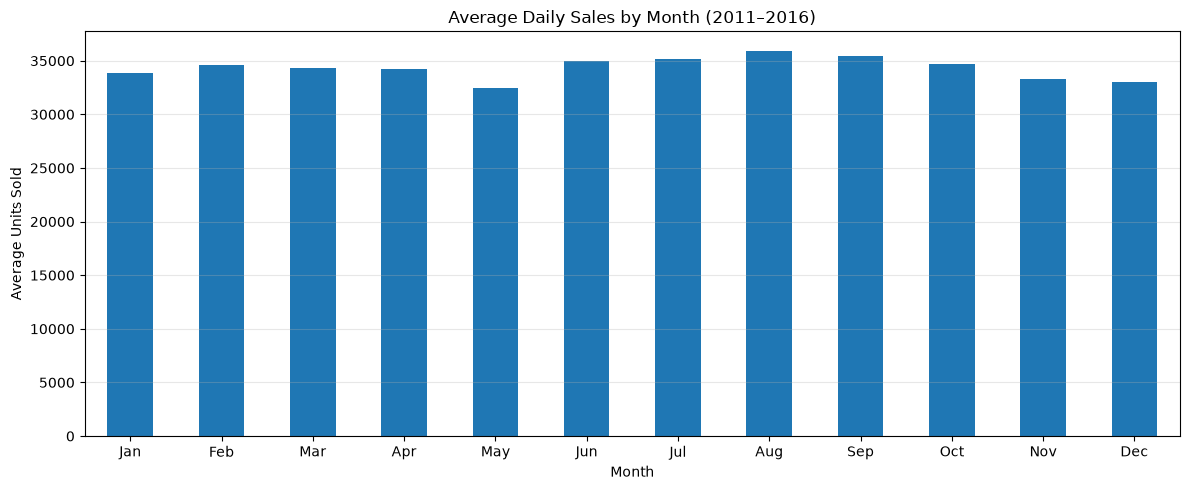

In [6]:
# Extract month and year
sales_calendar["month"] = sales_calendar["date"].dt.month
sales_calendar["year"] = sales_calendar["date"].dt.year

# Calculate average daily sales for each month
monthly_sales = (
    sales_calendar.groupby("month")["total_sales"]
    .mean()
)

# Arrange months in calendar order
monthly_sales = monthly_sales.sort_index()

print("Average Daily Sales by Month:")
display(monthly_sales.reset_index())

# Visualization
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="bar")

plt.title("Average Daily Sales by Month (2011–2016)")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(
    range(12),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Observations:
- Relatively higher average demand in July-September.                                    
- Lowest average demand in May.
- The average sale in November-December was lower too comparatively.
- August has the highest average daily sales across the observed years.

# 6. Yearly Sales Trend

Average Daily Sales by Year:


,year,total_sales
0,2011,26280.667656
1,2012,32955.838798
2,2013,35988.364384
3,2014,35862.400000
4,2015,37810.441096
5,2016,41309.973913


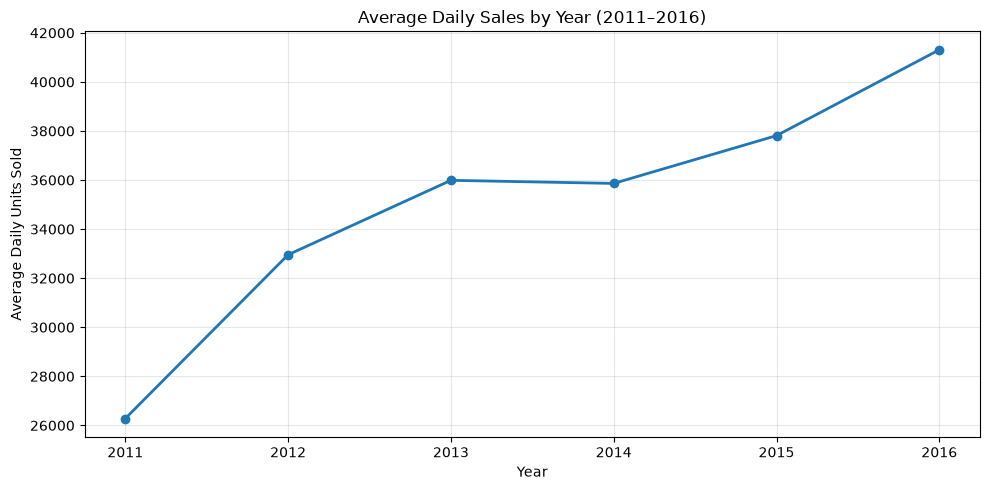

In [7]:
# Calculate average daily sales by year
yearly_sales = (
    sales_calendar.groupby("year")["total_sales"]
    .mean()
)

print("Average Daily Sales by Year:")
display(yearly_sales.reset_index())

# Visualization
plt.figure(figsize=(10, 5))

yearly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2
)

plt.title("Average Daily Sales by Year (2011–2016)")
plt.xlabel("Year")
plt.ylabel("Average Daily Units Sold")
plt.grid(alpha=0.3)
plt.xticks(yearly_sales.index)
plt.tight_layout()
plt.show()

Observation:
1. Overall growth: Average daily sales increased from around 26K in 2011 to 41K in 2016.
2. 2013–2014: Sales remained almost stable.
3. 2015–2016: Demand increased again.
4. 2016 is a partial year, so we shouldn't compare its total sales directly with complete years. Average daily sales is more suitable here.
This gives us evidence of a long-term upward trend.

# 7. Category-wise Sales Analysis

Purpose: Identify which product category contributes the most to total unit demand.

/tmp/ipykernel_25400/3347391053.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = daily_data.sum(axis=1)


Total Units Sold by Category:


,index,0
0,FOODS,45089939
1,HOUSEHOLD,14480670
2,HOBBIES,6124800


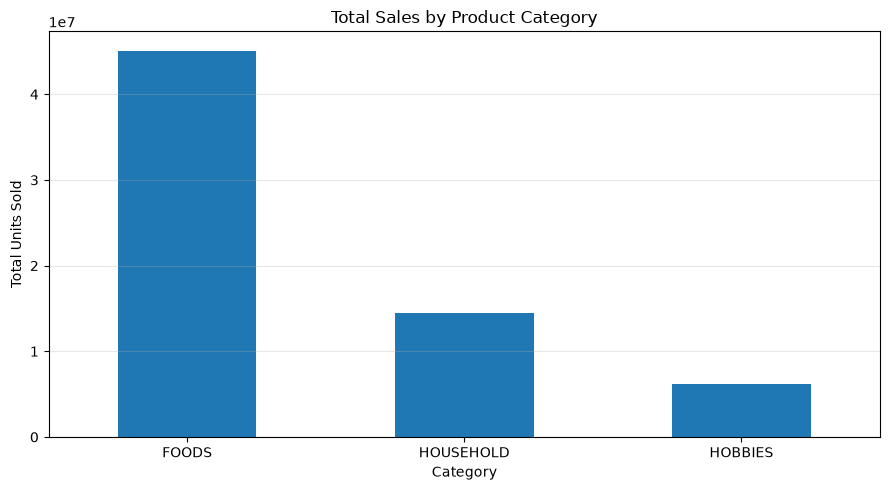

In [8]:
# Load product-category mapping
product_categories = pd.read_csv(
    SALES_PATH,
    usecols=["item_id", "cat_id"]
).drop_duplicates()

# Calculate total sales by product in chunks
category_sales = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):
    daily_data = chunk[daily_columns]

    chunk["total_units"] = daily_data.sum(axis=1)

    category_totals = chunk.groupby("cat_id")["total_units"].sum()

    for category, value in category_totals.items():
        category_sales[category] = (
            category_sales.get(category, 0) + value
        )

category_sales = pd.Series(category_sales).sort_values(
    ascending=False
)

print("Total Units Sold by Category:")
display(category_sales.reset_index())

# Visualization
plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Observations:
- FOODS contributes approximately 68.6% of total unit sales.
- HOUSEHOLD is the second-largest category.
- HOBBIES has the lowest sales volume.
This tells us that category-level demand is highly concentrated in FOODS.

# 8. Store-wise Sales Analysis

What we'll discover:
- Which store has the highest sales?
- Which store has the lowest sales?
- How different are the stores in terms of demand?

/tmp/ipykernel_25400/3348614761.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)


Total Sales by Store:


,index,0
0,CA_3,11188180
1,CA_1,7698216
2,TX_2,7214384
3,WI_2,6544012
4,WI_3,6427782
5,TX_3,6089330
6,CA_2,5685475
7,TX_1,5595292
8,WI_1,5149062
9,CA_4,4103676


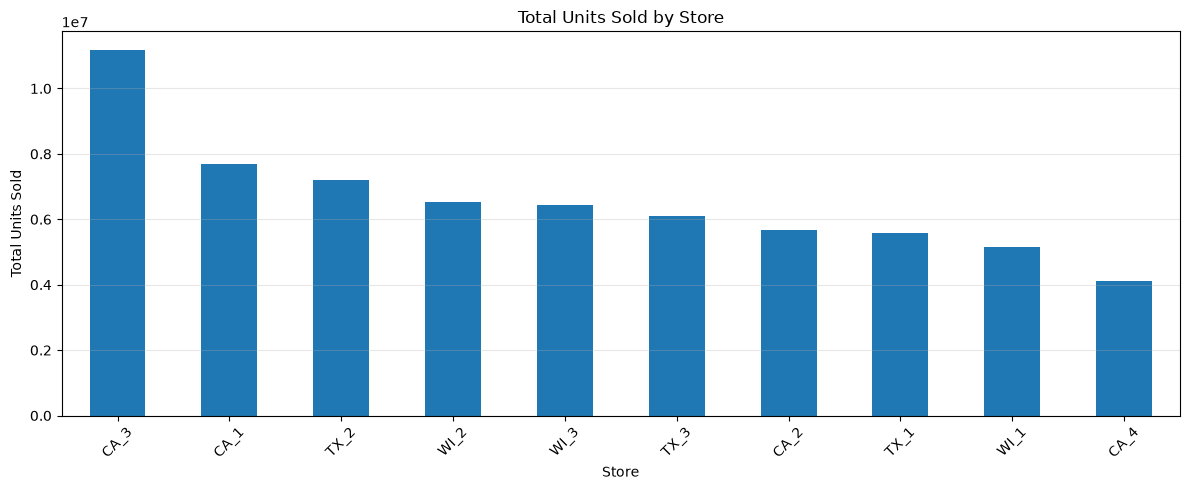

In [9]:
# Calculate total sales by store
store_sales = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):

    chunk["total_units"] = chunk[daily_columns].sum(axis=1)

    store_totals = chunk.groupby("store_id")["total_units"].sum()

    for store, value in store_totals.items():
        store_sales[store] = store_sales.get(store, 0) + value

store_sales = pd.Series(store_sales).sort_values(ascending=False)

print("Total Sales by Store:")
display(store_sales.reset_index())

# Visualization
plt.figure(figsize=(12, 5))

store_sales.plot(kind="bar")

plt.title("Total Units Sold by Store")
plt.xlabel("Store")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Observation :
CA_3 is the highest-selling store.



CA_4 has the lowest total sales.



CA_3 sells approximately 2.7 times as many units as CA_4.

/tmp/ipykernel_25400/605042316.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)


Total Sales by Department:


,index,0
0,FOODS_3,32372076
1,HOUSEHOLD_1,11500526
2,FOODS_2,7629822
3,HOBBIES_1,5596460
4,FOODS_1,5088041
5,HOUSEHOLD_2,2980144
6,HOBBIES_2,528340


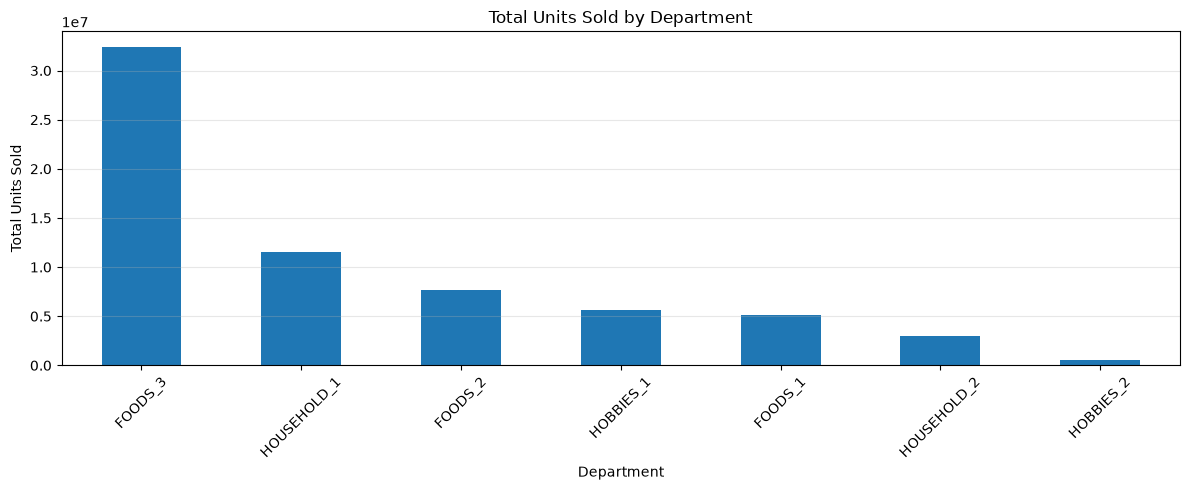

In [10]:
# Calculate total sales by department
department_sales = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):

    chunk["total_units"] = chunk[daily_columns].sum(axis=1)

    dept_totals = (
        chunk.groupby("dept_id")["total_units"].sum()
    )

    for dept, value in dept_totals.items():
        department_sales[dept] = (
            department_sales.get(dept, 0) + value
        )

department_sales = pd.Series(
    department_sales
).sort_values(ascending=False)

print("Total Sales by Department:")
display(department_sales.reset_index())

# Visualization
plt.figure(figsize=(12, 5))

department_sales.plot(kind="bar")

plt.title("Total Units Sold by Department")
plt.xlabel("Department")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 9. Department-wise Sales Analysis

What we'll discover:
- Which store has the highest sales?
- Which store has the lowest sales?
- How different are the stores in terms of demand?

/tmp/ipykernel_25400/3662158428.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)


Top 10 Best-Selling Products:


,index,0
0,FOODS_3_090,1002529
1,FOODS_3_586,920242
2,FOODS_3_252,565299
3,FOODS_3_555,491287
4,FOODS_3_714,396172
5,FOODS_3_587,396119
6,FOODS_3_694,390001
7,FOODS_3_226,363082
8,FOODS_3_202,295689
9,FOODS_3_723,284333


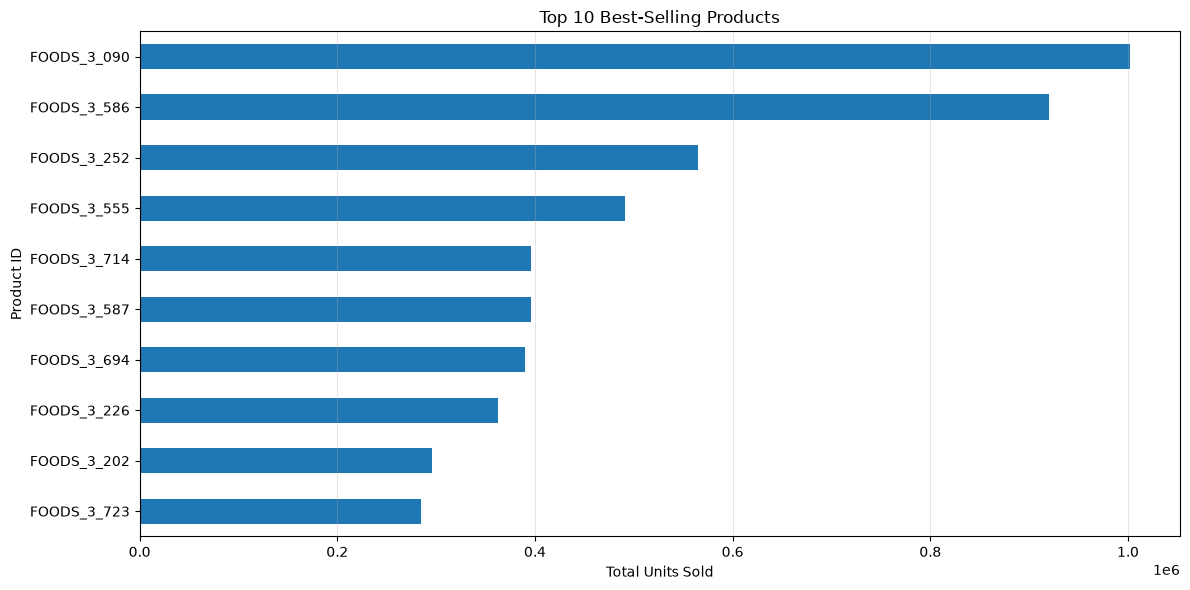

In [11]:
# Calculate total units sold by product
product_sales = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):

    chunk["total_units"] = chunk[daily_columns].sum(axis=1)

    product_totals = (
        chunk.groupby("item_id")["total_units"].sum()
    )

    for product, value in product_totals.items():
        product_sales[product] = (
            product_sales.get(product, 0) + value
        )

product_sales = pd.Series(product_sales).sort_values(
    ascending=False
)

top_10_products = product_sales.head(10)

print("Top 10 Best-Selling Products:")
display(top_10_products.reset_index())

# Visualization
plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Units Sold")
plt.ylabel("Product ID")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Observation :
- FOODS_3 alone contributes approximately 49.3% of all units sold.
- HOBBIES_2 has the lowest demand.
- FOODS_3 has roughly 61 times the unit sales of HOBBIES_2.
This is useful for inventory planning, but one thing to remember: high sales volume doesn't automatically mean high profit.

# 10. Top 10 Best Selling Products

Purpose: Identify high-demand products that may need higher inventory availability.

In [12]:
total_units_sold = product_sales.sum()
top_10_units = top_10_products.sum()

top_10_share = (top_10_units / total_units_sold) * 100

print("Total Units Sold:", total_units_sold)
print("Top 10 Products Units:", top_10_units)
print("Top 10 Products Sales Share:", round(top_10_share, 2), "%")

Total Units Sold: 65695409
Top 10 Products Units: 5104753
Top 10 Products Sales Share: 7.77 %


Observation :
- FOODS_3_090 is the best-selling product, with 1,002,529 units sold.
- FOODS_3_586 comes second, with 920,242 units.
- All top 10 products belong to the FOODS_3 department.
This suggests that FOODS_3 has several high-demand products, not just one bestseller.

# 11. Sales Share of Top 10 Products

In [13]:
total_units_sold = product_sales.sum()
top_10_units = top_10_products.sum()

top_10_share = (top_10_units / total_units_sold) * 100

print("Total Units Sold:", total_units_sold)
print("Top 10 Products Units:", top_10_units)
print("Top 10 Products Sales Share:", round(top_10_share, 2), "%")

Total Units Sold: 65695409
Top 10 Products Units: 5104753
Top 10 Products Sales Share: 7.77 %


Interpretation by the output :
- Most price records fall in the $2–$5 range.
- Very few records have prices above $20.
- The dataset is dominated by relatively low-priced products.

# 12. Demand vs Price Range

In [14]:
product_category = (
    pd.read_csv(SALES_PATH, usecols=["item_id", "cat_id"])
    .drop_duplicates(subset="item_id")
)

category_product_count = (
    product_category.groupby("cat_id")["item_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique Products in Each Category:")
display(category_product_count)

Unique Products in Each Category:


cat_id
FOODS        1437
HOUSEHOLD    1047
HOBBIES       565
Name: item_id, dtype: int64

In [15]:
category_sales = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):
    chunk["total_units"] = chunk[daily_columns].sum(axis=1)

    totals = chunk.groupby("cat_id")["total_units"].sum()

    for category, value in totals.items():
        category_sales[category] = (
            category_sales.get(category, 0) + value
        )

category_sales = pd.Series(category_sales)

category_avg_sales = (
    category_sales / category_product_count
).sort_values(ascending=False)

print("Average Historical Sales per Product:")
display(category_avg_sales)

/tmp/ipykernel_25400/429503957.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)


Average Historical Sales per Product:


FOODS        31377.828114
HOUSEHOLD    13830.630372
HOBBIES      10840.353982
dtype: float64

Price Dataset Shape: (6841121, 4)

Price Summary:


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

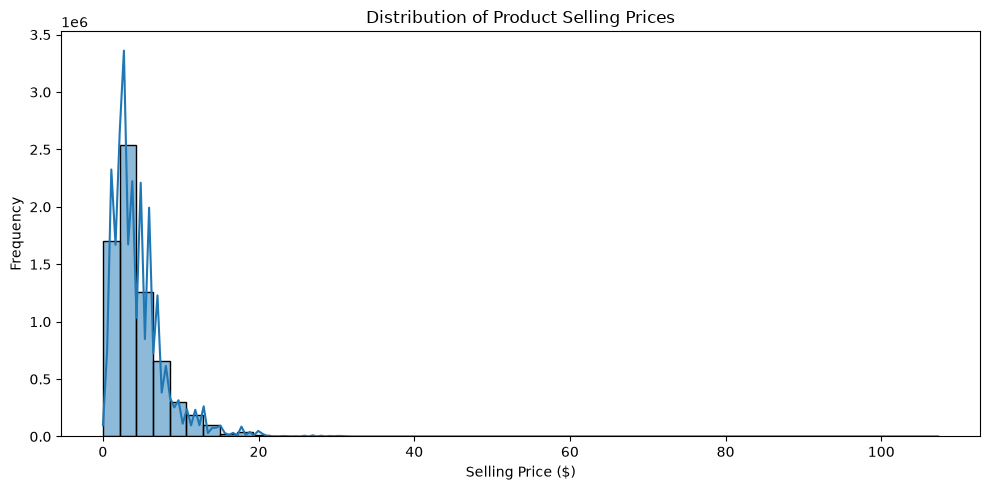

In [16]:
prices = pd.read_csv(PRICE_PATH)

print("Price Dataset Shape:", prices.shape)
print("\nPrice Summary:")
display(prices["sell_price"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    prices["sell_price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Product Selling Prices")
plt.xlabel("Selling Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [17]:
# Create price ranges
prices["price_range"] = pd.cut(
    prices["sell_price"],
    bins=[0, 2, 5, 10, 20, float("inf")],
    labels=["0-2", "2-5", "5-10", "10-20", "20+"]
)

print("Price Range Distribution:")
display(prices["price_range"].value_counts().sort_index())

Price Range Distribution:


price_range
0-2      1683124
2-5      3187118
5-10     1573084
10-20     372879
20+        24916
Name: count, dtype: int64

In [18]:
# Prepare product-store sales totals
sales_by_product_store = {}

for chunk in pd.read_csv(SALES_PATH, chunksize=5000):
    chunk["total_units"] = chunk[daily_columns].sum(axis=1)

    grouped = chunk.groupby(
        ["item_id", "store_id"]
    )["total_units"].sum()

    for key, value in grouped.items():
        sales_by_product_store[key] = value

sales_summary = pd.DataFrame(
    [
        (item, store, units)
        for (item, store), units in sales_by_product_store.items()
    ],
    columns=["item_id", "store_id", "total_units"]
)

print("Sales Summary Shape:", sales_summary.shape)
display(sales_summary.head())

/tmp/ipykernel_25400/3101221577.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)
/tmp/ipykernel_25400/3101221577.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)
/tmp/ipykernel_25400/3101221577.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.

Sales Summary Shape: (30490, 3)


/tmp/ipykernel_25400/3101221577.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)
/tmp/ipykernel_25400/3101221577.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  chunk["total_units"] = chunk[daily_columns].sum(axis=1)


,item_id,store_id,total_units
0,FOODS_1_001,CA_1,1503
1,FOODS_1_001,CA_2,2214
2,FOODS_1_002,CA_1,914
3,FOODS_1_002,CA_2,1154
4,FOODS_1_003,CA_1,1592


In [19]:
sales_price = sales_summary.merge(
    prices[["item_id", "store_id", "sell_price"]],
    on=["item_id", "store_id"],
    how="inner"
)

print("Merged Dataset Shape:", sales_price.shape)
display(sales_price.head())

Merged Dataset Shape: (6841121, 4)


,item_id,store_id,total_units,sell_price
0,FOODS_1_001,CA_1,1503,2.0
1,FOODS_1_001,CA_1,1503,2.0
2,FOODS_1_001,CA_1,1503,2.0
3,FOODS_1_001,CA_1,1503,2.0
4,FOODS_1_001,CA_1,1503,2.0


In [20]:
# Map daily sales columns to calendar weeks
day_week = calendar[["d", "wm_yr_wk"]].copy()

print("Calendar Week Mapping:")
display(day_week.head())

print("Unique Weeks:", day_week["wm_yr_wk"].nunique())

Calendar Week Mapping:


,d,wm_yr_wk
0,d_1,11101
1,d_2,11101
2,d_3,11101
3,d_4,11101
4,d_5,11101


Unique Weeks: 282


In [21]:
weekly_sales_parts = []

# Map each daily column to its week
week_map = (
    calendar.set_index("d")["wm_yr_wk"]
    .to_dict()
)

# Process sales in chunks
for chunk in pd.read_csv(SALES_PATH, chunksize=500):

    for week, days in day_week.groupby("wm_yr_wk"):

        week_columns = days["d"].tolist()

        available_days = [
            col for col in week_columns
            if col in chunk.columns
        ]

        if not available_days:
            continue

        weekly_total = chunk[available_days].sum(axis=1)

        temp = pd.DataFrame({
            "item_id": chunk["item_id"].values,
            "store_id": chunk["store_id"].values,
            "wm_yr_wk": week,
            "units_sold": weekly_total.values
        })

        weekly_sales_parts.append(temp)

weekly_sales = pd.concat(
    weekly_sales_parts,
    ignore_index=True
)

print("Weekly Sales Shape:", weekly_sales.shape)
display(weekly_sales.head())

Weekly Sales Shape: (8354260, 4)


,item_id,store_id,wm_yr_wk,units_sold
0,HOBBIES_1_001,CA_1,11101,0
1,HOBBIES_1_002,CA_1,11101,0
2,HOBBIES_1_003,CA_1,11101,0
3,HOBBIES_1_004,CA_1,11101,0
4,HOBBIES_1_005,CA_1,11101,0


In [22]:
print("Total Weekly Records:", len(weekly_sales))
print("Unique Products:", weekly_sales["item_id"].nunique())
print("Unique Stores:", weekly_sales["store_id"].nunique())
print("Unique Weeks:", weekly_sales["wm_yr_wk"].nunique())

print("\nWeekly Sales Summary:")
display(weekly_sales["units_sold"].describe())

Total Weekly Records: 8354260
Unique Products: 3049
Unique Stores: 10
Unique Weeks: 274

Weekly Sales Summary:


count    8.354260e+06
mean     7.863702e+00
std      2.364762e+01
min      0.000000e+00
25%      0.000000e+00
50%      2.000000e+00
75%      7.000000e+00
max      3.539000e+03
Name: units_sold, dtype: float64

In [23]:
price_lookup = prices[
    ["item_id", "store_id", "wm_yr_wk", "price_range"]
]

price_demand_results = []

for start in range(0, len(weekly_sales), 500000):

    sales_chunk = weekly_sales.iloc[start:start + 500000]

    merged_chunk = sales_chunk.merge(
        price_lookup,
        on=["item_id", "store_id", "wm_yr_wk"],
        how="inner"
    )

    summary = merged_chunk.groupby(
        "price_range",
        observed=False
    ).agg(
        total_units=("units_sold", "sum"),
        weekly_records=("units_sold", "count")
    )

    price_demand_results.append(summary)

price_demand = (
    pd.concat(price_demand_results)
    .groupby(level=0)
    .sum()
)

price_demand["avg_weekly_demand"] = (
    price_demand["total_units"] /
    price_demand["weekly_records"]
)

display(price_demand)

,total_units,weekly_records,avg_weekly_demand
price_range,,,
0-2,33848380,1625143,20.827939
2-5,23626584,3071847,7.691328
5-10,6916431,1516763,4.559995
10-20,1214851,359630,3.378058
20+,89163,23818,3.743513


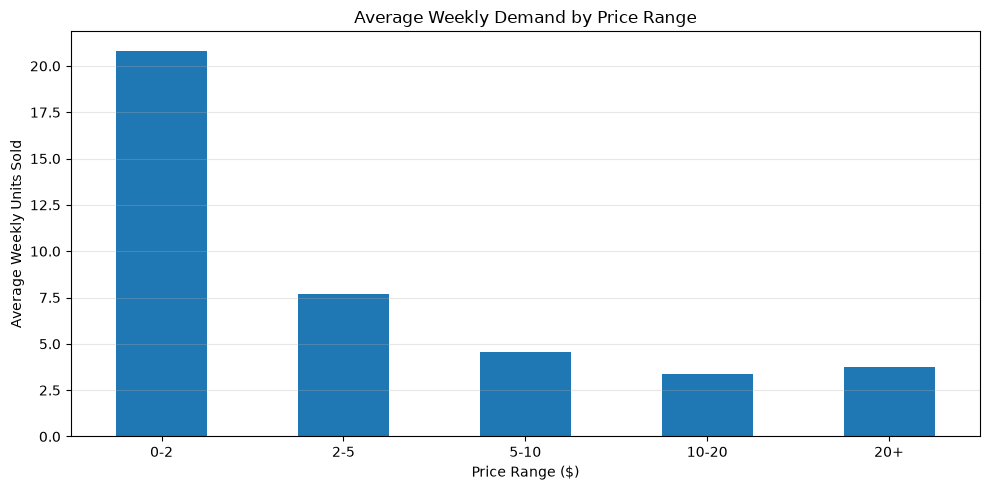

In [24]:
plt.figure(figsize=(10, 5))

price_demand["avg_weekly_demand"].plot(
    kind="bar",
    rot=0
)

plt.title("Average Weekly Demand by Price Range")
plt.xlabel("Price Range ($)")
plt.ylabel("Average Weekly Units Sold")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Saving the Price-Demand analysis

In [25]:
price_demand.to_csv(
    PROCESSED_DIR / "price_demand_analysis.csv"
)

print("Price-Demand Analysis Saved!")
print(
    "File Exists:",
    (PROCESSED_DIR / "price_demand_analysis.csv").exists()
)

Price-Demand Analysis Saved!
File Exists: True
